In [257]:
# -*- coding: utf-8 -*-
"""
Created on Wed Apr 19 12:08:27 2017

@author: atarasen
"""
import numpy as np
import matplotlib.pyplot as plt

from scipy import ndimage


import os, sys
sys.path.append('/home/cercache/users/atarasen/codes/python/')
sys.path.append('/home3/homedir7/perso/atarasen/codes/python/collocation')

import nice_functions as nf
reload (nf)

<module 'nice_functions' from '/home/cercache/users/atarasen/codes/python/nice_functions.pyc'>

In [255]:
def compute_window_mean_and_var_strided(image, window_w, window_h):
    w, h = image.shape
    strided_image = np.lib.stride_tricks.as_strided(image, 
                                                    shape=[w - window_w + 1, h - window_h + 1, window_w, window_h],
                                                    strides=image.strides + image.strides)
    # important: trying to reshape image will create complete 4-dimensional compy
    means = strided_image.mean(axis=(2,3)) 
    mean_squares = (strided_image ** 2).mean(axis=(2, 3)) 
    maximums = strided_image.max(axis=(2,3))
    
    variations = mean_squares - means ** 2
    return means, maximums, variations 


def make_window(lx, ly):
#create a Kernel - square matrix of type:
# [[2 1 2]
#  [1 0 1]
#  [2 1 2]]
    a = np.ones(ly)
    c = np.zeros((lx, ly),)
    c[0] = np.arange(0, ly)

    for i in range(1, lx):                       
        c[i] = c[i-1]+a

    window = np.zeros((lx*2 - 1, ly*2 - 1), )
    window[0:lx, 0:ly] = np.flipud(np.fliplr(c)) ; window[(lx-1):, (ly-1):] = c
    window += np.flipud(window)
    
#     correct the middle line and middle column that are double now (#ts not the error to do it twice)
    window[0:lx, 0:ly] = np.flipud(np.fliplr(c)); window[(lx-1):, (ly-1):] = c 
    window[lx-1, ly-1] = 1
    return window


def dist_window(lx, ly):
    #DONT USE IT YET, NOT FINISHED AND DONT GIVE PROPER ANSWER
    c = np.ones((lx, ly),)
     
    for i in range(lx):
        for j in range(ly):            
            if np.logical_and(i==(lx-1), j==(ly-1))==False:
                c[i, j] = np.sqrt(np.square(lx - i)+np.square(ly-j))
#     print c
    
    window = np.ones((lx*2 - 1, ly*2 - 1), )
    
    window[0:lx, 0:ly] = c;
    window[(lx-1):, :ly] = np.flipud(c)
#     print "step 1"
#     print window
    
#     print np.fliplr(window[:, :(ly)])

    window[:, (ly-1):] = np.fliplr(window[:, :(ly)])
#     print "step 2"
#     print window

    
    return window


def im_regularity_naive(image, lx, ly, plot_cond = False, mask_cond = False, norm_cond = False):
    w, h = image.shape
    #print ' image.shape:', w, h
    smooth_filter = dist_window(lx, ly)
#     print "Filter kernel:", smooth_filter
    
    window_h, window_w = smooth_filter.shape

    smoothed_data = np.zeros([w, h])
    
    lx_new = lx-1 #lx not-the-py-style
    ly_new  = ly-1
    for i in range(lx_new, w-lx_new):
        for j in range(ly_new, h-ly_new):
            window = image[(i-lx_new):(i+lx), (j-ly_new):(j+ly)]                     
            smoothed_data[(i-lx_new):(i+lx), (j-ly_new):(j+ly)] += window*(smooth_filter**(-1))
                            
    if norm_cond == True:
        smoothed_data = smoothed_data/(lx*2-1) 
        
    if mask_cond == True:
        mask = np.ones(smoothed_data.shape)
        mask[(lx-1):h-(lx-1), :][:, (ly-1):w-(ly-1)]=0    
        smoothed_data = np.ma.array(smoothed_data, mask = mask)
   

    if plot_cond == True:
        plt.pcolormesh(smoothed_data)
        plt.clim(0, 10)
        plt.colorbar()
        plt.show()    
        
    #print 'smoothed_data.shape', smoothed_data.shape    
    return smoothed_data


def im_regularity_sqrt(image, lx, ly):
# one "for" loop doesnt help much to fasten the process 
    dim0, dim1 = image.shape
    smoothed = np.zeros((dim0, dim1),)

    
    filter_window = dist_window(lx, ly)
    filter_window_flat = (filter_window**(-1)).ravel()

# trying to adapt to 1D - 2D indeces        
    mask_lxly = np.ones((dim0, dim1),)
    mask_lxly[lx:(dim0-(lx-1)), ly:(dim0-(ly-1))] = 0
    mask_lxly_flat = mask_lxly.ravel()
    
    ind_x, ind_y = np.meshgrid(np.arange(dim0), np.arange(dim1))
    ind_x_flat = ind_x.ravel(); ind_y_flat = ind_y.ravel()
#     print ind_x_flat
    for ind_1d in range(image.shape[0]*image.shape[1]):
        if mask_lxly_flat[ind_1d]==0:
#         print 'ind_1d', ind_1d
            x = ind_x_flat[ind_1d]
            y = ind_y_flat[ind_1d]
#         cond_x = np.logical_and(x>=lx, x<=(dim0-(lx-1)))
#         cond_y = np.logical_and(y>=lx, y<=(dim1-(ly-1)))
        
#         print "x", x, "y", y
#         print "cond_x", cond_x,  '; cond_y', cond_y, '; np.logical_and(cond_x,  cond_y)', np.logical_and(cond_x,  cond_y)
#         print np.logical_and(cond_x,  cond_y)
        
#         if np.logical_and(cond_x,  cond_y)==True:  
            data_window_flat = image[(-lx+x):(lx+x-1), (-ly+y):(ly+y-1)].ravel()
#             print 'data_window_flat', data_window_flat.shape
#             print 'filter_window_flat', filter_window_flat.shape
            smoothed[(-lx+x):(lx+x-1), (-ly+y):(ly+y-1)] += (data_window_flat*filter_window_flat).reshape([2*lx-1, 2*ly-1])
#             plt.pcolormesh(smoothed)
#             plt.show()
            
    return smoothed
   

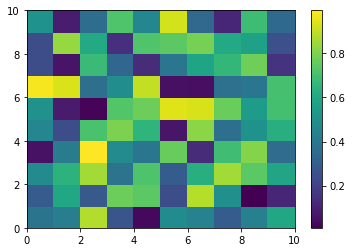

kernel size 3
Naive:
Elapsed time is 0.000624179840088 seconds.
One D:
Elapsed time is 0.000704050064087 seconds.
kernel size 5
Naive:
Elapsed time is 0.000455141067505 seconds.
One D:
Elapsed time is 0.000502824783325 seconds.


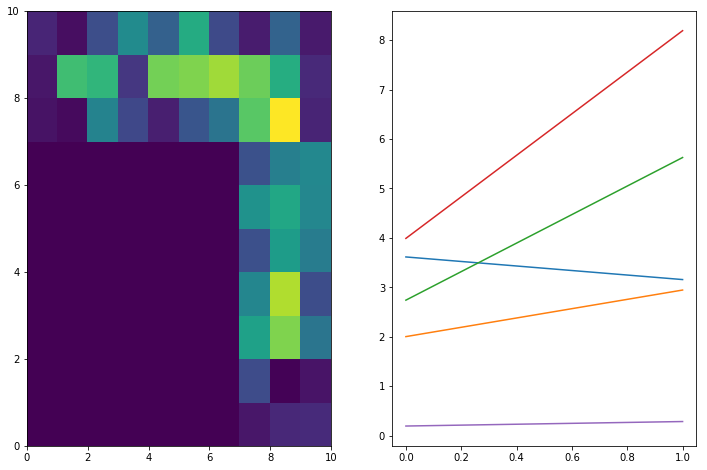

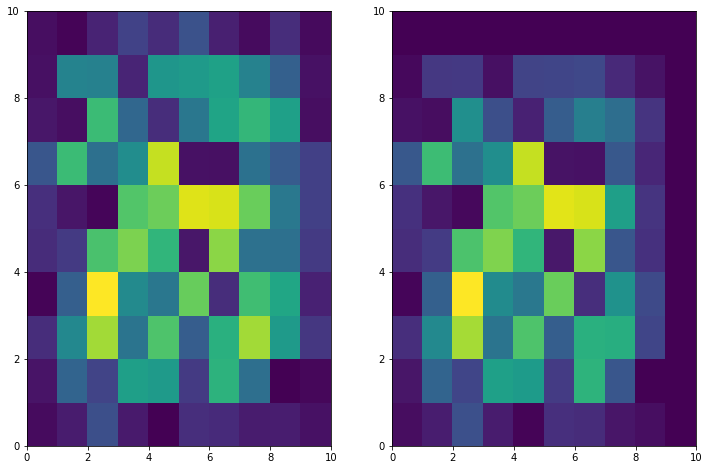

In [263]:
plt.close('all')
image = np.random.rand(10, 10)

fig0 = plt.figure(1)
plt.pcolormesh(image)
plt.colorbar()
plt.show()


# lx = 2; ly = 2
# window = dist_window(lx, ly)
# print 'result',  window
list_filt_layers = np.arange(2, 4)
smoothed1 = np.zeros((image.shape[0], image.shape[1], len(list_filt_layers)),)
smoothed2 = np.zeros((image.shape[0], image.shape[1], len(list_filt_layers)),)

for i_l, l in enumerate(list_filt_layers):
    print "kernel size", l*2-1
    lx = l; ly = l
    print 'Naive:'
    nf.tic()
    smoothed1[:,:,i_l] = im_regularity_naive(image, lx, ly)
    
    n = nf.toc()

    print 'One D:'
    nf.tic()
    smoothed2[:,:,i_l] = im_regularity_sqrt(image, lx, ly)
    oned = nf.toc()

    
fig = plt.figure(2, figsize=(12, 8))
ax1  = fig.add_subplot(121)
plt.pcolormesh(smoothed1[:,:,0]-smoothed2[:,:,0])
plt.colorbar

ax2  = fig.add_subplot(122)
axis_x = np.arange(len(list_filt_layers))
# for ipp in range(25, 75):
for ipp in range(2, 7):

    plt.plot(axis_x, smoothed1[ipp, ipp, :])
    # plt.colorbar()
plt.show()



fig = plt.figure(3, figsize=(12, 8))
ax1  = fig.add_subplot(121)
plt.pcolormesh(smoothed1[:,:,0])
plt.colorbar

ax2  = fig.add_subplot(122)
plt.pcolormesh(smoothed2[:,:,0])
plt.colorbar

plt.show()

# result_image = im_regularity_sqrt(image, lx, ly)

In [217]:
def im_regulariry_strided(image, lx, ly):
#     suppose that the window_h(eight) and window_w(idth) are different from that one of the whole image
    smooth_filter = make_window(lx, ly)
    window_h, window_w = smooth_filter.shape
    print "kernel shape:",  smooth_filter.shape, 'image shape:', image.shape

    w, h = image.shape
    strided_image = np.lib.stride_tricks.as_strided(image, 
                                                    shape=[w - window_w + 1, h - window_h + 1, window_w, window_h],
                                                    strides=image.strides + image.strides)
    # important: trying to reshape image will create complete 4-dimensional compy
    
    print strided_image
    smoothed_data = strided_image*((window)**(-1))     
    return smoothed_data









def im_regularity_filter(image, lx, ly):
    #not the same thing that I was doing with n"naive" 2 loops approach
    def filter2d(footprint_elements, weights):
    # this ".sum()"  in the end is not exactly what i need: 
    # i don't want to sum up all the values inside the window, i want to add up the windows as small matrices...
 
        return (footprint_elements*(weights.ravel()**(-1))).sum() 
    w, h = image.shape
    
    weights = make_window(lx, ly)
    print "Filter kernel:", weights
    
    footprint = np.ones(weights.shape)
#     func = lambda x: (x)**(-1)
    
    smoothed_data = ndimage.generic_filter(image, filter2d, footprint=footprint, extra_arguments=((weights,)))
    
    return smoothed_data




def im_regularity_sqrt_weird(image, lx, ly):
    w, h = image.shape
    result_image = np.zeros([w, h])
    ind_x, ind_y = np.meshgrid(np.arange(w), np.arange(h))
    
    ind_x = ind_x.ravel()
    ind_y = ind_y.ravel()

    valid = image[lx:-lx, ly:-ly]
    ind_nonvalid = np.where(image!=valid)
    print ind_nonvalid
    

    
    
    
    for ind_1d in range(image.shape[0]*image.shape[1]):
        print ind_1d
        if ind_1d!=ind_nonvalid:
            x = ind_x[ind_1d]; y = ind_y[ind_1d]
            print x, y

            data_window = image[(-lx+x):(lx+x), (-ly+y):(ly+y)].ravel()
            x_i = ind_x[(-lx+x):(lx+x), (-ly+y):(ly+y)].ravel(); y_i = ind_y[(-lx+x):(lx+x), (-ly+y):(ly+y)].ravel()

            dist=[]
            for ii in range(len(data_window)):
                dist.append(np.sqrt(np.square(x - x_i[ii])+np.square(y - y_i[ii])))
            
            dist[dist==0]=1
            fnc = dist**(-1)
            result_image[(-lx+x):(lx+x), (-ly+y):(ly+y)] = (data_window*fnc).reshape(lx*2-1, ly*2-1)
    return result_image
            

(10, 10)


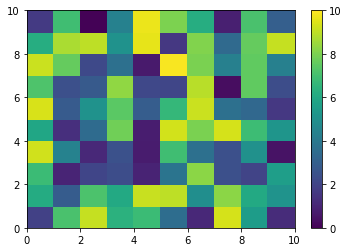

[[ 6.  5.  4.  3.  4.  5.  6.]
 [ 5.  4.  3.  2.  3.  4.  5.]
 [ 4.  3.  2.  1.  2.  3.  4.]
 [ 3.  2.  1.  1.  1.  2.  3.]
 [ 4.  3.  2.  1.  2.  3.  4.]
 [ 5.  4.  3.  2.  3.  4.  5.]
 [ 6.  5.  4.  3.  4.  5.  6.]]


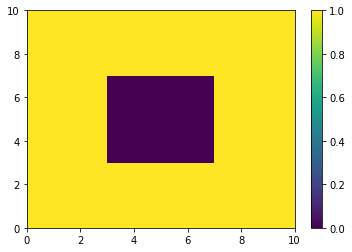

Elapsed time is 0.227229118347 seconds.
Filter kernel: [[ 6.  5.  4.  3.  4.  5.  6.]
 [ 5.  4.  3.  2.  3.  4.  5.]
 [ 4.  3.  2.  1.  2.  3.  4.]
 [ 3.  2.  1.  1.  1.  2.  3.]
 [ 4.  3.  2.  1.  2.  3.  4.]
 [ 5.  4.  3.  2.  3.  4.  5.]
 [ 6.  5.  4.  3.  4.  5.  6.]]
Elapsed time is 0.00224018096924 seconds.


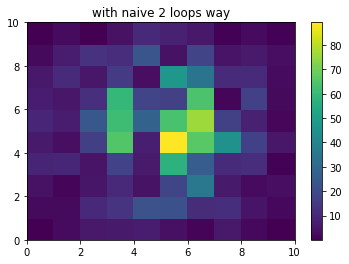

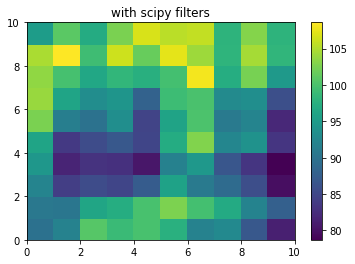

In [35]:
image = np.random.rand(10, 10)*10
print image.shape

plt.pcolormesh(image)
plt.clim(0, 10)
plt.colorbar()
plt.show()


lx = 4; ly = 4

# means, maximums, variations  = compute_window_mean_and_var_strided(image, 4, 4)

# smoothed_data = im_regulariry_strided(image, 2, 2)
nf.tic()
smoothed_data1, i, j, smoothed_data_masked = im_regularity_naive(image, lx, ly)
nf.toc()

nf.tic()
smoothed_data2 = im_regularity_filter(image, lx, ly)
nf.toc()    


plt.figure(1)
plt.pcolormesh(smoothed_data1)
# plt.clim(0, 10)
plt.colorbar()
plt.title('with naive 2 loops way')
plt.show()


plt.figure(2)
plt.pcolormesh(smoothed_data2)
# plt.clim(0, 10)
plt.colorbar()
plt.title('with scipy filters')
plt.show()

In [70]:

lx = 4; ly = 4
smooth_filter = make_window(lx, ly)

print smooth_filter
print (smooth_filter)**(-1)


[[ 6.  5.  4.  3.  4.  5.  6.]
 [ 5.  4.  3.  2.  3.  4.  5.]
 [ 4.  3.  2.  1.  2.  3.  4.]
 [ 3.  2.  1.  1.  1.  2.  3.]
 [ 4.  3.  2.  1.  2.  3.  4.]
 [ 5.  4.  3.  2.  3.  4.  5.]
 [ 6.  5.  4.  3.  4.  5.  6.]]
[[ 0.16666667  0.2         0.25        0.33333333  0.25        0.2
   0.16666667]
 [ 0.2         0.25        0.33333333  0.5         0.33333333  0.25        0.2       ]
 [ 0.25        0.33333333  0.5         1.          0.5         0.33333333
   0.25      ]
 [ 0.33333333  0.5         1.          1.          1.          0.5
   0.33333333]
 [ 0.25        0.33333333  0.5         1.          0.5         0.33333333
   0.25      ]
 [ 0.2         0.25        0.33333333  0.5         0.33333333  0.25        0.2       ]
 [ 0.16666667  0.2         0.25        0.33333333  0.25        0.2
   0.16666667]]


In [ ]:
#     # Flatten to re-check if points are inside the overlap area    
#         flat_regular_lat=regular_lat.ravel()
#         flat_regular_lon=regular_lon.ravel()
#         mask_flat=np.ones(flat_regular_lat.shape)

#         points_collection =[Point(lat_i, lon_i) for lat_i, lon_i in zip(flat_regular_lat, flat_regular_lon)]

#         for i_point, point in enumerate(points_collection):
#             if c.geom_type =='MultiPolygon':
#                 for one_poly in c:
#                     if one_poly.contains(point)==True:
#                         mask_flat[i_point] = 0
#             else:
#                 if c.contains(point)==True:
#                         mask_flat[i_point] = 0
#         mask_2d = mask_flat.reshape(regular_shape)    
#         regular_s1 = ma.array(regular_s1, mask=mask_2d)
        